# Vern Pivot Cross Statistics — ES

Each insight has a heading, brief description and findings summary, followed by its saved chart or table. The same selected results appear on Narada.

Open this file in a notebook editor with a Python 3 kernel. Each question has its own Markdown cell and a short, visible Python display cell. Outputs are already included. Run the setup cell, then any insight, or run all cells to redisplay the saved evidence. Keep `insight_view.py`, `saved-reports.json` and `assets/` in this folder. Redisplaying uses standard Python and does not execute the research calculations.

Eligible samples span January 3, 2020–September 18, 2026: 875 pivot-matched RTH, 1,308 VWAP-only RTH and 1,292 full-Globex sessions. Requested coverage extends through October 30, 2026. Historical pivot availability is unverified, eligibility is retrospective and conditional views are exploratory. Forward outcomes are RTH-only; fills, costs and profitability were not tested.

Saved source run: `20261031_ranked_v2`. Each summary describes its stated saved baseline.

In [1]:
# Load the saved evidence viewer beside this notebook.
from pathlib import Path
from importlib.util import module_from_spec, spec_from_file_location

_relative_folders = (
    "work/30_verniman_pivot_statistics_es/notebook",
    "reports/exports/30_verniman_pivot_statistics_es/20261031_ranked_v2/20261103_readable_notebook_v3",
)
_start = Path.cwd().resolve()
_candidates = []
for _ancestor in (_start, *_start.parents):
    _candidates.extend([_ancestor, *(_ancestor / name for name in _relative_folders)])
_folder = next((folder for folder in _candidates
                if (folder / "insight_view.py").is_file()
                and (folder / "saved-reports.json").is_file()), None)
if _folder is None:
    raise FileNotFoundError("Keep insight_view.py, saved-reports.json and assets beside the notebook; start the kernel in that folder.")
_spec = spec_from_file_location("vern_pivot_insight_view", _folder / "insight_view.py")
_view = module_from_spec(_spec)
_spec.loader.exec_module(_view)
show_insight = _view.show_insight


# Vern Pivot Cross Statistics — ES

The pivot analysis uses 875 eligible RTH sessions matched to a single source pivot and its exact ES delivery contract. Its VWAP comparisons use those same sessions. Actual eligible dates span January 3, 2020–September 18, 2026; requested coverage through October 30 extends beyond retained market data.

Crossings are actual strict-side transitions on completed three-minute closes. EMA6 already on one side, a touch, or an equal value is a different state. VWAP uses one-minute HLC3 and volume from 18:00 New York; the EMA20/50 cloud uses five-minute closes.

Each insight describes its named saved baseline, then shows a chart or compact supporting rows. The companion notebook uses the same prose and evidence. Ranked statistics retains the fuller tables and filters. Selected CSVs and eligible-period bounds are below. Historical pivot availability remains unverified; eligibility is retrospective and conditional slices are exploratory. Fills, costs and profitability were not tested.

## How often does EMA6 cross Globex VWAP on pivot-matched days?

Count actual completed three-minute EMA6–VWAP transitions during regular trading hours (RTH). Keep every eligible session, including sessions with no cross; this is the pivot-matched population.

**Findings summary.** Across 875 pivot-matched RTH sessions, EMA6 crossed VWAP 2,450 times: a saved mean of 2.80 crossings per session and median of 2.00. The chart shows selected saved frequency views; these are descriptive counts.

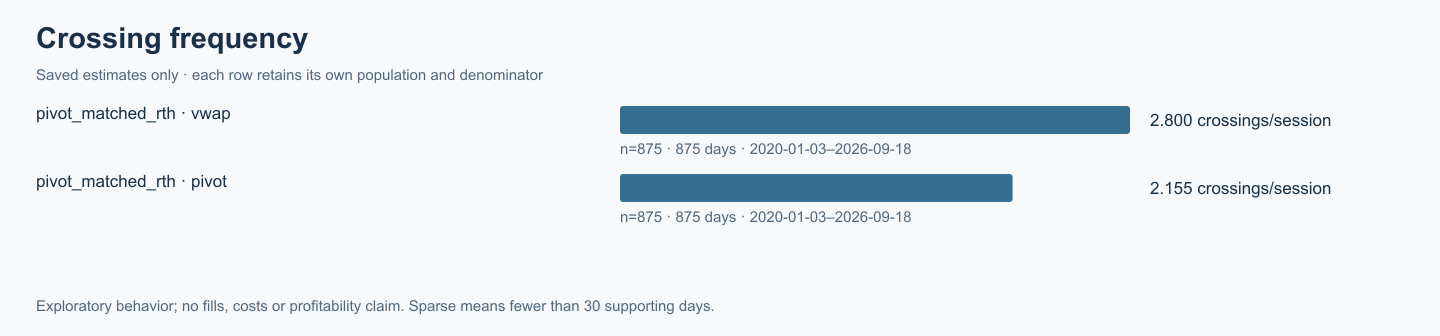

In [2]:
show_insight('pivot', 's01')


## How often does EMA6 cross the daily pivot?

Measure actual EMA6 line transitions through the fixed daily pivot. An EMA already on one side at the opening is an initial state, and touching or equalling the pivot alone is not a new cross.

**Findings summary.** The 875 eligible sessions contained 1,886 EMA6–pivot crossings. The saved mean was 2.16 crossings per session and the median was 1.00; zero-cross days remain in the denominator.

In [3]:
show_insight('pivot', 's02')


Saved measure and context,Mean,Count / sum,Median,Observations,Days
Pivot-matched RTH · overall: all · Crosses [crossings/session] · EMA6–pivot,2.155,"1,886.000",1.000,875,875


## How common are days without an EMA crossing?

Compare the saved zero, one, two, three-to-four and five-plus crossing categories. Daily counts concern actual EMA6 crossings; a zero count is an observed outcome rather than missing evidence.

**Findings summary.** Within the same 875 pivot-matched RTH sessions, 26.9% had no EMA6–pivot cross and 21.0% had no EMA6–VWAP cross. The earlier Ranked statistics reports retain all count categories and their exact session denominators.

In [4]:
show_insight('pivot', 's03')


Saved measure and context,Share,Observations,Days
Pivot-matched RTH · overall: all · Count bucket [fraction] · EMA6–pivot · cross count=0,26.9%,875,875
Pivot-matched RTH · overall: all · Count bucket [fraction] · EMA6–VWAP · cross count=0,21.0%,875,875


## What is the crossing rate per observed hour?

Use each day’s observed native three-minute exposure to express EMA6 crossing frequency per hour. Section lengths differ, so an hourly rate answers a different question from a raw section count.

**Findings summary.** Across 875 pivot-matched RTH sessions, the saved mean daily rate was 0.33 EMA6–pivot crossings per observed hour and 0.43 EMA6–VWAP crossings per observed hour. No observed exposure would be unavailable rather than a zero rate.

In [5]:
show_insight('pivot', 's04')


Saved measure and context,Mean,Observations,Days
Pivot-matched RTH · overall: all · Crosses per hour [crossings/hour] · EMA6–pivot,0.332,875,875
Pivot-matched RTH · overall: all · Crosses per hour [crossings/hour] · EMA6–VWAP,0.431,875,875


## How do price and EMA6 crossing counts differ?

Compare completed three-minute price-close transitions and actual EMA6 transitions through the pivot on the same eligible sessions. The saved additional-price-cross measure is a within-session difference.

**Findings summary.** For the same 875 pivot-matched RTH sessions, price averaged 4.64 pivot crossings per session and EMA6 averaged 2.16. These are recurrence counts; they do not measure the profitability of taking either event.

In [6]:
show_insight('pivot', 's05')


Saved measure and context,Mean,Observations,Days
Pivot-matched RTH · overall: all · Crosses [crossings/session] · Price–pivot,4.639,875,875
Pivot-matched RTH · overall: all · Crosses [crossings/session] · EMA6–pivot,2.155,875,875


## How often does a price break return before EMA confirmation?

Start with price breaks whose EMA6 was initially unconfirmed, and follow them until an actual EMA confirmation or a return through the pivot. Initially aligned cases are separate, and unresolved episodes are censored.

**Findings summary.** A return preceded EMA confirmation in 1,075 of 2,445 resolved episodes (44.0%), supported by 666 distinct days. Another 33 episodes were censored. The return label becomes known later than the original price break.

In [7]:
show_insight('pivot', 's06')


Saved measure and context,Share,Count / sum,Observations,Days,Unavailable,Censored
Pivot-matched RTH · overall: all · Returned before confirmation [fraction] · Price–pivot,44.0%,"1,075.000","2,445",666,33,33


## How deep are breaks that return without EMA confirmation?

Describe the directional penetration beyond the pivot for initially unconfirmed price breaks that returned before a new EMA6 cross. Membership is a later path outcome; it is not an entry-time filter.

**Findings summary.** The 1,075 returned unconfirmed breaks, spanning 494 distinct days, had mean penetration of 3.13 ES points and median penetration of 2.50 points. This conditional depth describes the observed returned episodes.

In [8]:
show_insight('pivot', 's07')


Saved measure and context,Mean,Median,Observations,Days,Unavailable,Censored
Pivot-matched RTH · overall: all · Returned unconfirmed depth [points] · Price–pivot,3.132,2.500,"1,075",494,"1,403",33


## How much time and movement precede delayed EMA confirmation?

Measure the lag from an initially unconfirmed price break to the subsequent actual EMA6–pivot crossing, while that price episode remains active. Forward outcomes after confirmation start at the confirmation close.

**Findings summary.** Among 1,370 delayed confirmations on 577 distinct days, mean delay was 5.07 minutes and mean directional movement before confirmation was 3.35 ES points. These figures concern episodes that eventually confirmed, not every initial price break.

In [9]:
show_insight('pivot', 's08')


Saved measure and context,Mean,Observations,Days
Pivot-matched RTH · overall: all · Confirmation delay [minutes] · Price–pivot · confirmation kind=delayed,5.074,"1,370",577
Pivot-matched RTH · overall: all · Movement before confirmation [points] · Price–pivot · confirmation kind=delayed,3.355,"1,370",577


## What happens 30 minutes after an EMA6–pivot crossing?

Measure price displacement in the direction of the actual EMA6–pivot cross, from its observable close to a complete 30-minute endpoint within RTH. Earlier signal-bar extremes and incomplete late-session paths are excluded.

**Findings summary.** Across 1,790 complete 30-minute outcomes on 636 distinct days, mean directional displacement was -0.04 ES points and 48.8% ended strictly positive. A further 96 candidate outcomes were unavailable; these are price-path statistics.

In [10]:
show_insight('pivot', 's09')


Saved measure and context,Mean,Share,Observations,Days,Unavailable,Censored
Pivot-matched RTH · overall: all · Displacement [points] · EMA6–pivot · 30m,-0.040,Not available,"1,790",636,96,96
Pivot-matched RTH · overall: all · Positive movement [fraction] · EMA6–pivot · 30m,Not available,48.8%,"1,790",636,96,96


## How far does price travel in either direction after the crossing?

Measure favorable and adverse excursions over complete 30-minute paths after actual EMA6–pivot crossings, plus fixed point-reach frequencies. Both sides can be reached on one path; no fill or intraminute ordering is inferred.

**Findings summary.** For 1,790 complete paths on 636 distinct days, mean favorable excursion was 9.04 ES points and mean adverse excursion was 8.65 points. The saved share reaching 10 favorable points was 30.8%.

In [11]:
show_insight('pivot', 's10')


Saved measure and context,Mean,Share,Observations,Days,Unavailable,Censored
Pivot-matched RTH · overall: all · Favorable excursion [points] · EMA6–pivot · 30m,9.040,Not available,"1,790",636,96,96
Pivot-matched RTH · overall: all · Adverse excursion [points] · EMA6–pivot · 30m,8.648,Not available,"1,790",636,96,96
Pivot-matched RTH · overall: all · Favorable reach 10 [fraction] · EMA6–pivot · 30m,Not available,30.8%,"1,790",636,96,96


## How often does EMA6 avoid recrossing the pivot for 30 minutes?

Look for the next reverse EMA6–pivot cross within a complete 30-minute RTH window. This is an EMA line recross, separate from price returning through the pivot. Late or missing windows remain censored.

**Findings summary.** No reverse EMA6 cross occurred in 1,110 of 1,790 complete 30-minute windows (62.0%), supported by 636 distinct days. Another 96 windows were censored; absence of a recross does not imply a profitable price move.

In [12]:
show_insight('pivot', 's11')


Saved measure and context,Share,Count / sum,Observations,Days,Unavailable,Censored
Pivot-matched RTH · overall: all · No recross [fraction] · EMA6–pivot · 30m,62.0%,"1,110.000","1,790",636,96,96


## When does the first EMA6–pivot crossing occur?

Time the first actual EMA6–pivot crossing from the 09:30 RTH opening. Conditional timing excludes days without a cross, while the timing-bin shares and the explicit no-cross category retain all eligible days.

**Findings summary.** On the 640 days with an EMA6–pivot cross, the first cross occurred a mean 57.04 minutes after 09:30, with median 24.00 minutes. There were 235 no-cross days. The chart shows the first chronological timing bins, not the entire distribution.

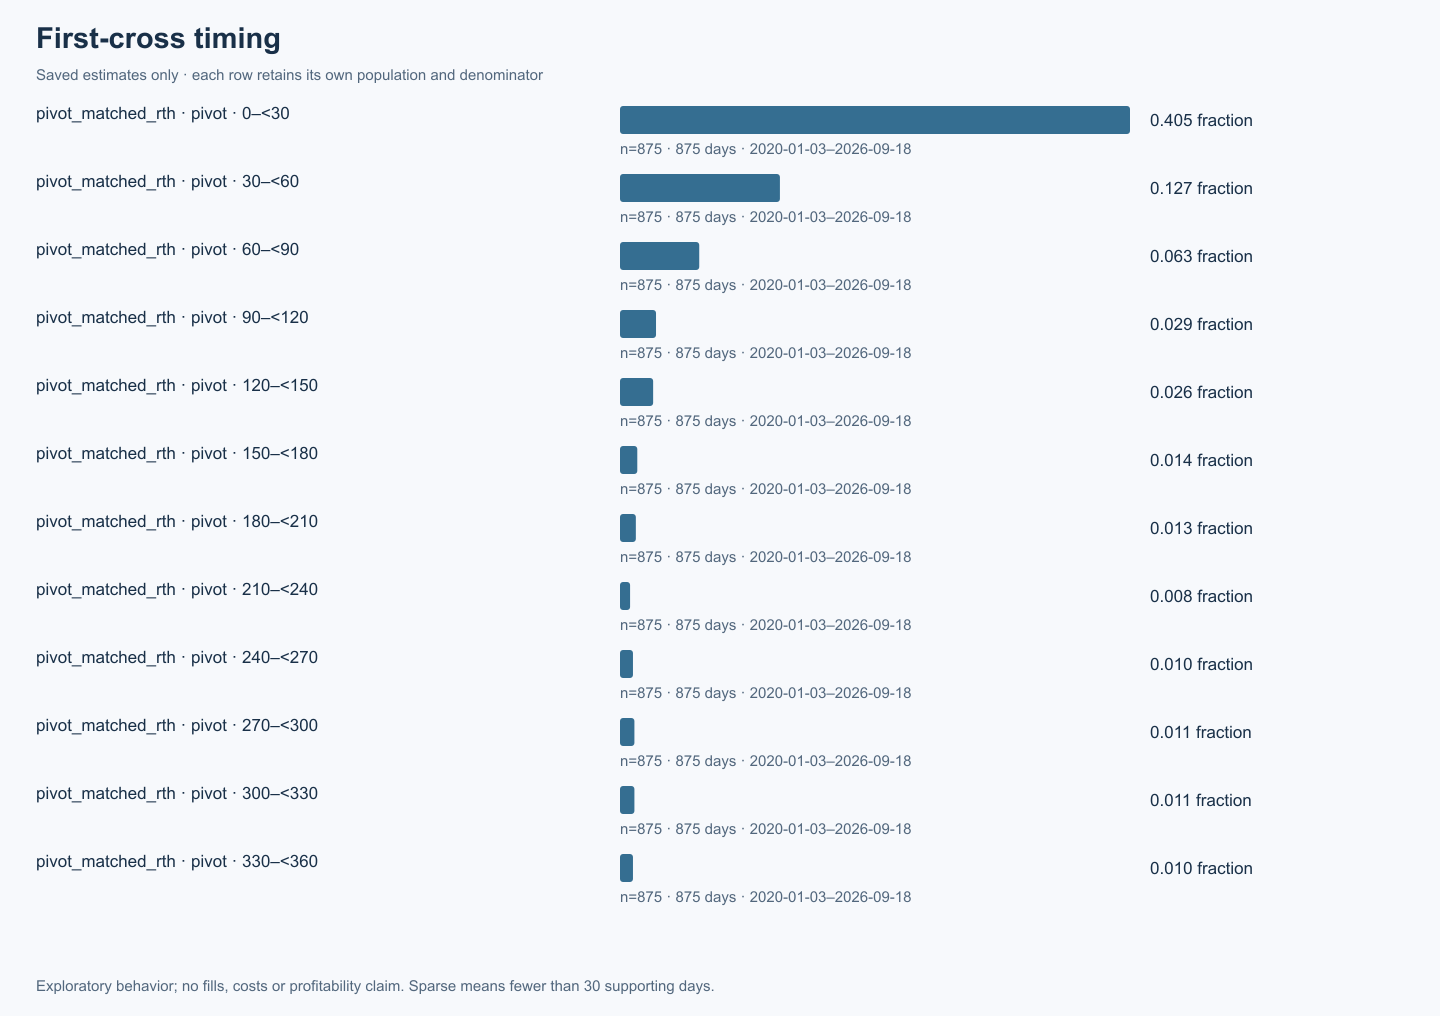

In [13]:
show_insight('pivot', 's12')


## Does followthrough differ between first and later crossings?

Separate each day’s first, second and third-or-later actual EMA6–pivot crossings, then measure complete 30-minute directional displacement. Repeated events on one day are dependent; the ordinal groups are exploratory comparisons.

**Findings summary.** Saved mean 30-minute displacement was -0.18 ES points after the first crossing (636 outcomes), 0.69 points after the second (419 outcomes), and -0.33 points after third-or-later crossings. Full support and censoring remain in the table.

In [14]:
show_insight('pivot', 's13')


Saved measure and context,Mean,Observations,Days,Unavailable,Censored
Pivot-matched RTH · overall: all · Displacement [points] · EMA6–pivot · 30m · crossing ordinal=1,-0.180,636,636,4,4
Pivot-matched RTH · overall: all · Displacement [points] · EMA6–pivot · 30m · crossing ordinal=2,0.689,419,419,14,14
Pivot-matched RTH · overall: all · Displacement [points] · EMA6–pivot · 30m · crossing ordinal=3+,-0.335,735,284,78,78


## Does EMA6 reach VWAP before reversing through the pivot?

After an actual EMA6–pivot cross, follow strictly at-risk sequences for a same-direction VWAP crossing before a reverse pivot crossing, within 30 minutes. Simultaneous crosses, already-beyond states and censored sequences remain separate.

**Findings summary.** EMA6 crossed VWAP before recrossing the pivot in 362 of 705 resolved or fully observed at-risk sequences (51.3%), supported by 429 distinct days. Another 20 sequences were censored; excluded starting configurations are retained in the earlier Ranked statistics reports.

In [15]:
show_insight('pivot', 's14')


Saved measure and context,Share,Count / sum,Observations,Days,Unavailable,Censored
Pivot-matched RTH · overall: all · Second before recross [fraction] · EMA6–pivot · 30m · first reference=pivot,51.3%,362.000,705,429,"1,181",20


## How does the opening configuration relate to later crossings?

Group days by whether the actual 09:30 opening price is above both pivot and VWAP, below both, between them or on a boundary. These opening states are distinct from future session outcomes.

**Findings summary.** Mean daily EMA6–pivot crossing counts were 1.99 on 362 above-both days, 2.18 on 209 below-both days, and 2.35 on between-line days. These saved conditional counts do not establish a predictive advantage.

In [16]:
show_insight('pivot', 's15')


Saved measure and context,Mean,Observations,Days
Pivot-matched RTH · overall: all · Crosses [crossings/session] · EMA6–pivot · opening configuration=above both,1.986,362,362
Pivot-matched RTH · overall: all · Crosses [crossings/session] · EMA6–pivot · opening configuration=below both,2.177,209,209
Pivot-matched RTH · overall: all · Crosses [crossings/session] · EMA6–pivot · opening configuration=between,2.352,293,293


## What does cloud support or opposition look like after a pivot cross?

Classify the five-minute EMA20/50 cloud using its ordering and both 15-minute slopes at the actual crossing. Supporting, opposing, mixed/flat and unknown states remain distinct; outcomes use complete 30-minute RTH paths.

**Findings summary.** Mean 30-minute directional displacement after EMA6–pivot crossings was -0.31 ES points with cloud support (645 outcomes) and 0.57 points with cloud opposition (393 outcomes). These exploratory slices are not independent confirmation of an edge.

In [17]:
show_insight('pivot', 's16')


Saved measure and context,Mean,Observations,Days,Unavailable,Censored
Pivot-matched RTH · overall: all · Displacement [points] · EMA6–pivot · 30m · cloud support=support,-0.310,645,446,38,38
Pivot-matched RTH · overall: all · Displacement [points] · EMA6–pivot · 30m · cloud support=opposition,0.574,393,286,26,26


## How far apart are pivot and VWAP at the opening?

Measure the absolute pivot–VWAP distance at 09:30 in ES points and basis points, then retain the protocol’s fixed separation bands for later crossing and outcome views. The bands were not fitted to the saved outcomes.

**Findings summary.** Across 875 pivot-matched days, mean opening separation was 9.48 ES points and 19.80 basis points. These are separately saved averages of daily measures; the earlier Ranked statistics reports retain crossing and outcome slices by the fixed opening bands.

In [18]:
show_insight('pivot', 's17')


Saved measure and context,Mean,Observations,Days
Pivot-matched RTH · overall: all · Opening separation points [points] · EMA6–pivot,9.479,875,875
Pivot-matched RTH · overall: all · Opening separation bps [basis points] · EMA6–pivot,19.800,875,875


## How often does price retest the pivot after an EMA6 crossing?

After an actual EMA6–pivot crossing, identify the first subsequent completed three-minute bar containing the fixed pivot within 30 minutes. Incidence requires the full window; observed touch-bar hold, failure and equality are separate outcomes.

**Findings summary.** A pivot retest occurred in 1,134 of 1,790 complete 30-minute windows (63.4%), supported by 636 distinct days. Another 96 incidence windows were censored. This bar-based touch definition does not infer intrabar execution.

In [19]:
show_insight('pivot', 's18')


Saved measure and context,Share,Count / sum,Observations,Days,Unavailable,Censored
Pivot-matched RTH · overall: all · Pivot retest [fraction] · EMA6–pivot · 30m,63.4%,"1,134.000","1,790",636,96,96


## Which section-end states persist into the next section?

Compare saved cloud ordering and price-side states at section endpoints. Opening range ends at 10:30, AM ends at 12:30 and PM ends at 16:00 New York. These are endpoint-to-endpoint descriptions, not opening-time predictors.

**Findings summary.** In the pivot-matched population, bullish cloud ordering persisted from the opening-range endpoint to the AM endpoint on 75.4% of 468 eligible bullish-source days; bearish ordering persisted on 68.6% of 407 bearish-source days. The chart includes selected saved transition states.

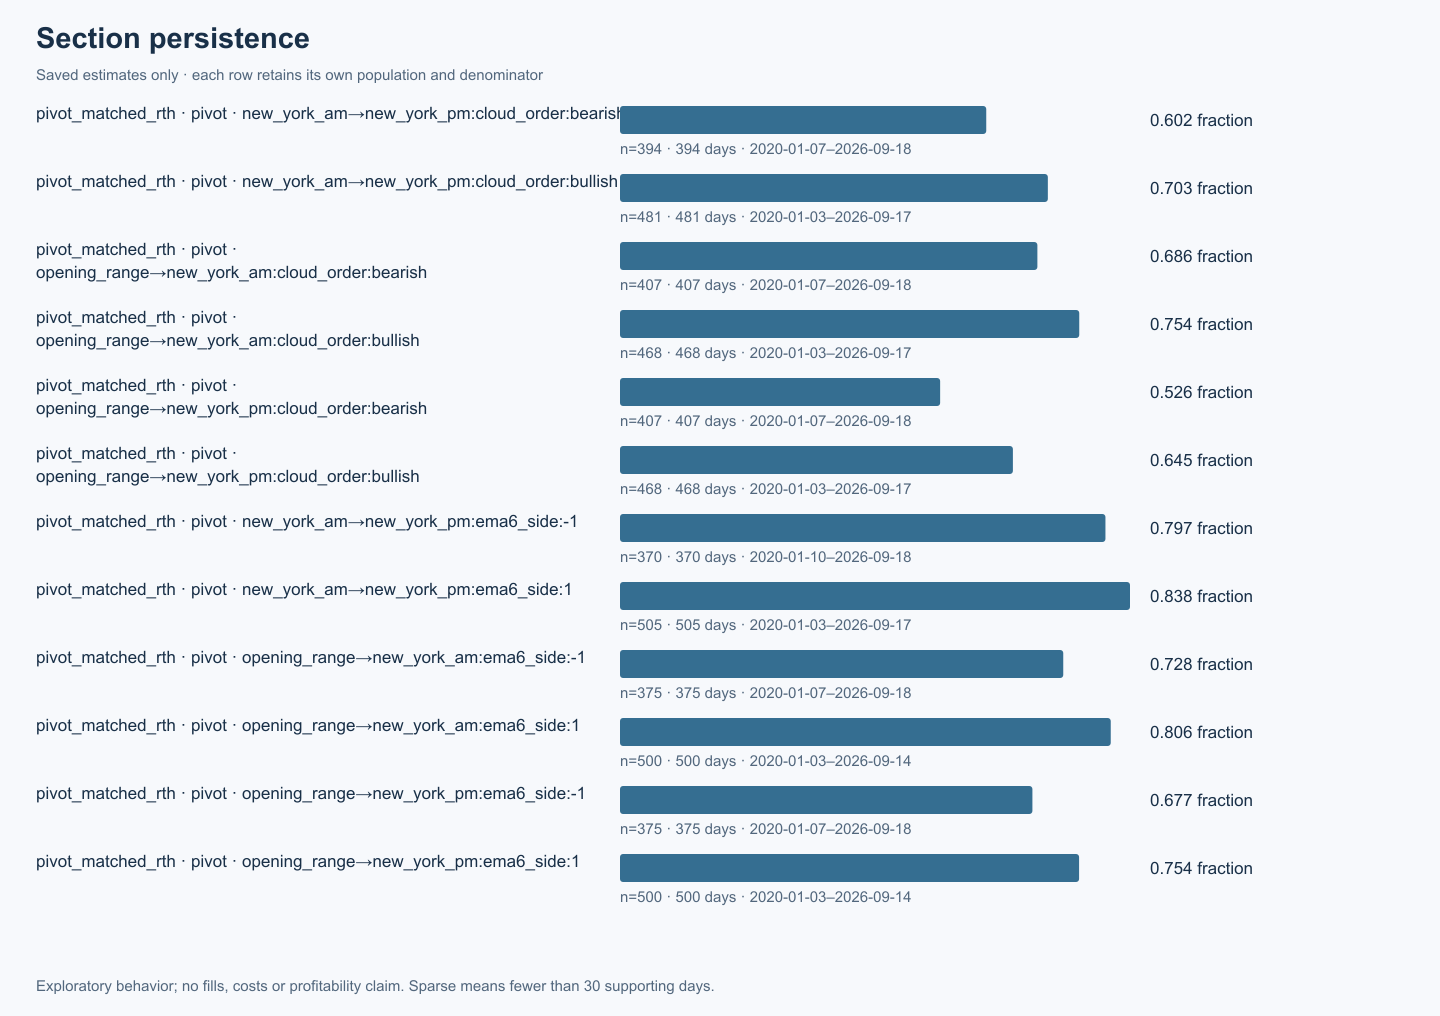

In [20]:
show_insight('pivot', 's19')


## How do recent crossings compare with earlier history?

Compare trailing 20, 60 and 120 eligible observed sessions against their separate preceding histories, with each recent window excluded from its comparator. The requested cutoff is October 30, 2026, but actual retained evidence ends September 18.

**Findings summary.** EMA6–VWAP crossings averaged 3.25 per RTH session over the last 20 eligible pivot-matched sessions, versus 2.79 over the disjoint preceding 855 sessions. The 20-session cell is sparse under the study’s 30-day rule; dates and longer windows remain explicit.

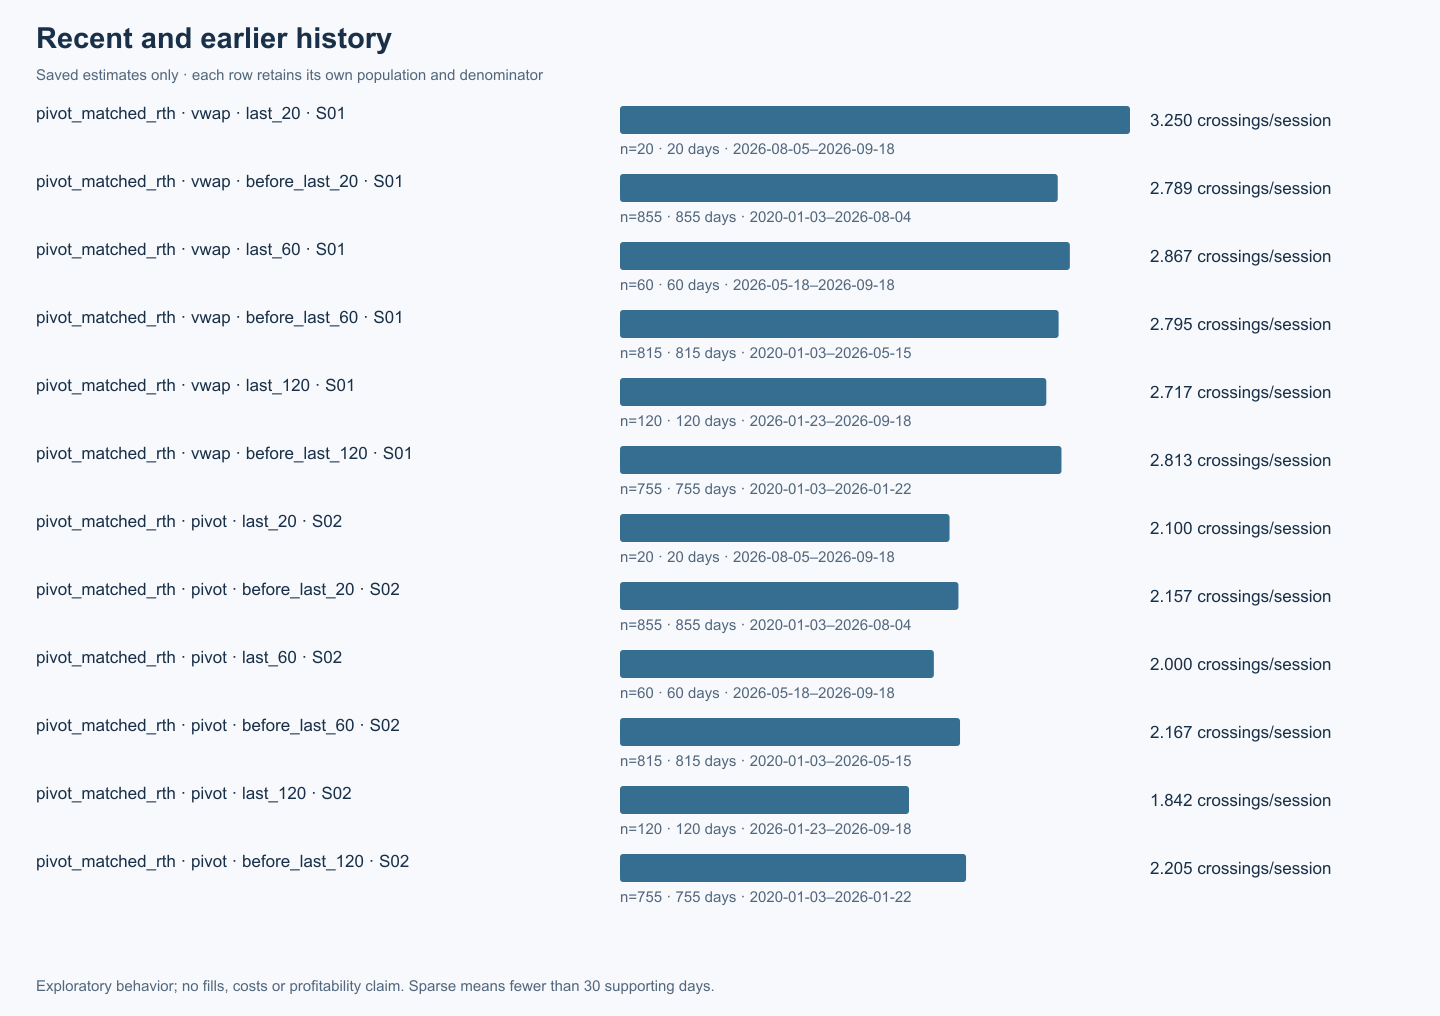

In [21]:
show_insight('pivot', 's20')


## Evidence qualifications

Repository-retained ES data only; requested coverage ends 2026-10-30, while retained market data ends 2026-09-18. Missing dates/contracts and retrospective full-day eligibility limit generalization.

Historical pivot available_at remains unverified. Nominal 09:25 timing does not establish a historically executable pre-open signal.

Returned-without-EMA and eventual confirmation labels are known later. Already-aligned EMA6 is distinct from an actual new line crossing.

Signed displacement and excursions describe price paths. No entries, fills, costs or net profitability are tested. Broad slices are exploratory.

This extends an already observed completed study and is not an untouched holdout. EMA–VWAP crossings use the moving difference, carry strict side through equality, clear unknown comparisons and exclude anchor initialization. EMA recrosses are separate from price reversals. Pivot retests remain fixed-pivot only. Five-observed-session moving-block intervals use 2,000 replicates, seed 20261031; within-day events remain together. Broad conditional slices are exploratory.

# Vern Pivot Cross Statistics — Globex VWAP

The VWAP analysis keeps 1,308 eligible RTH sessions and 1,292 full-Globex sessions separate. It does not require a matched daily pivot. Forward outcomes are RTH-only. Actual eligible dates span January 3, 2020–September 18, 2026; requested coverage through October 30 extends beyond retained market data.

Crossings are actual strict-side transitions on completed three-minute closes. EMA6 already on one side, a touch, or an equal value is a different state. VWAP uses one-minute HLC3 and volume from 18:00 New York; the EMA20/50 cloud uses five-minute closes.

Each insight describes its named saved baseline, then shows a chart or compact supporting rows. The companion notebook uses the same prose and evidence. Ranked statistics retains the fuller tables and filters. Selected CSVs and eligible-period bounds are below. Historical pivot availability remains unverified; eligibility is retrospective and conditional slices are exploratory. Fills, costs and profitability were not tested.

## How often does EMA6 cross VWAP in Globex and RTH?

Count actual completed three-minute EMA6–VWAP transitions in two separate pivot-independent populations: full Globex and regular trading hours. Globex initializes at 18:00 New York; the VWAP reset itself is not a crossing.

**Findings summary.** The full-Globex mean was 10.78 crossings per session across 1,292 eligible sessions. The separate RTH mean was 2.89 across 1,308 sessions. Their observation windows and eligible populations differ; the chart preserves those identities.

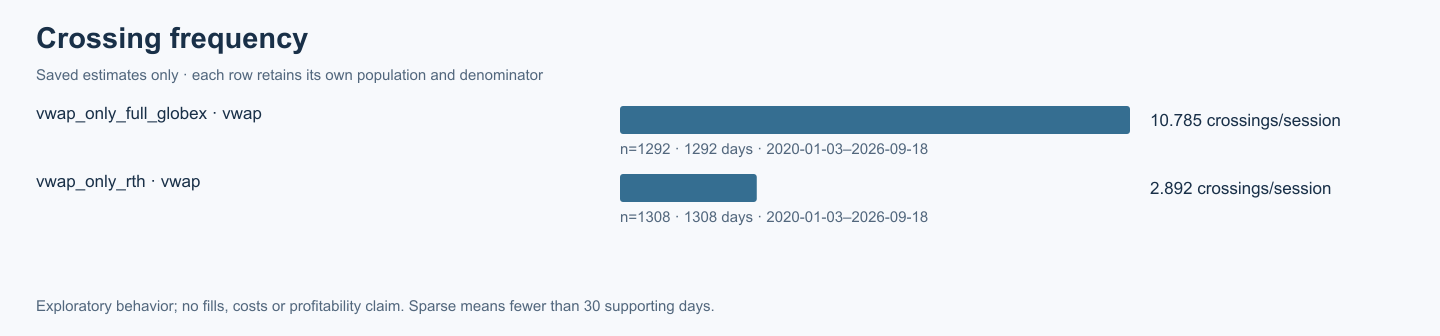

In [22]:
show_insight('vwap', 's01')


## How often are there no crossings or repeated VWAP crossings?

Read the fixed daily EMA6–VWAP count categories independently for full Globex and RTH. Full Globex covers a longer observation window, so its raw daily counts should retain their separate scope.

**Findings summary.** Among 1,292 full-Globex sessions, 0.7% had no EMA6–VWAP crossing and 90.5% had five or more. In the separate 1,308-session RTH population, 20.6% had no crossing.

In [23]:
show_insight('vwap', 's03')


Saved measure and context,Share,Observations,Days
Full Globex · overall: all · Count bucket [fraction] · EMA6–VWAP · cross count=0,0.7%,"1,292","1,292"
Full Globex · overall: all · Count bucket [fraction] · EMA6–VWAP · cross count=5+,90.5%,"1,292","1,292"
VWAP-only RTH · overall: all · Count bucket [fraction] · EMA6–VWAP · cross count=0,20.6%,"1,308","1,308"


## What are the VWAP crossing rates per observed hour?

Express each day’s actual EMA6–VWAP crossings per observed native three-minute hour. Scheduled closures contribute no exposure, and unknown exposure is not an observed zero.

**Findings summary.** The saved mean daily rate was 0.47 crossings per observed hour across 1,292 full-Globex sessions, and 0.44 across 1,308 separate RTH sessions. These exposure-normalized means preserve each population’s eligibility rules.

In [24]:
show_insight('vwap', 's04')


Saved measure and context,Mean,Observations,Days
Full Globex · overall: all · Crosses per hour [crossings/hour] · EMA6–VWAP,0.470,"1,292","1,292"
VWAP-only RTH · overall: all · Crosses per hour [crossings/hour] · EMA6–VWAP,0.445,"1,308","1,308"


## How often does price cross VWAP compared with EMA6?

Compare completed three-minute price-close and EMA6 transitions against contemporaneous moving VWAP on the same named population. This compact view cites full-Globex rows; the earlier Ranked statistics reports retain both Globex and RTH selections without pooling them.

**Findings summary.** On the same 1,292 full-Globex sessions, price averaged 25.08 VWAP crossings per session while EMA6 averaged 10.78. These are counts of distinct event definitions, not assumed trading opportunities.

In [25]:
show_insight('vwap', 's05')


Saved measure and context,Mean,Observations,Days
Full Globex · overall: all · Crosses [crossings/session] · Price–VWAP,25.077,"1,292","1,292"
Full Globex · overall: all · Crosses [crossings/session] · EMA6–VWAP,10.785,"1,292","1,292"


## What happens 30 minutes after an RTH EMA6–VWAP crossing?

Measure directional price displacement from the observable EMA6–VWAP event close over a complete 30-minute RTH path. The full-Globex recurrence population is not used for overnight forward outcomes.

**Findings summary.** Across 3,551 complete RTH outcomes on 1,030 distinct days, mean 30-minute directional displacement was 0.02 ES points and 50.1% ended strictly positive. Another 232 candidate outcomes were unavailable; no trade fills or costs are modeled.

In [26]:
show_insight('vwap', 's09')


Saved measure and context,Mean,Share,Observations,Days,Unavailable,Censored
VWAP-only RTH · overall: all · Displacement [points] · EMA6–VWAP · 30m,0.016,Not available,"3,551","1,030",232,232
VWAP-only RTH · overall: all · Positive movement [fraction] · EMA6–VWAP · 30m,Not available,50.1%,"3,551","1,030",232,232


## How large are the favorable and adverse VWAP-cross paths?

Measure excursions and fixed point reaches after actual EMA6–VWAP crossings using complete 30-minute RTH paths. Favorable and adverse reaches can both occur, and the saved summaries do not infer intraminute order.

**Findings summary.** For 3,551 complete paths on 1,030 distinct days, mean favorable excursion was 8.72 ES points and mean adverse excursion was 8.35 points. The share reaching 10 favorable points was 31.0%. These are path measures rather than realized returns.

In [27]:
show_insight('vwap', 's10')


Saved measure and context,Mean,Share,Observations,Days,Unavailable,Censored
VWAP-only RTH · overall: all · Favorable excursion [points] · EMA6–VWAP · 30m,8.717,Not available,"3,551","1,030",232,232
VWAP-only RTH · overall: all · Adverse excursion [points] · EMA6–VWAP · 30m,8.351,Not available,"3,551","1,030",232,232
VWAP-only RTH · overall: all · Favorable reach 10 [fraction] · EMA6–VWAP · 30m,Not available,31.0%,"3,551","1,030",232,232


## How often does EMA6 avoid recrossing VWAP for 30 minutes?

Observe the next reverse EMA6–VWAP transition within a complete 30-minute RTH window. Require the entire window even when a reverse is already observed, and preserve late or missing windows as censored.

**Findings summary.** No reverse EMA6–VWAP cross occurred in 2,173 of 3,551 complete windows (61.2%), supported by 1,030 distinct days. Another 232 windows were censored; this describes line persistence rather than directional trading profit.

In [28]:
show_insight('vwap', 's11')


Saved measure and context,Share,Count / sum,Observations,Days,Unavailable,Censored
VWAP-only RTH · overall: all · No recross [fraction] · EMA6–VWAP · 30m,61.2%,"2,173.000","3,551","1,030",232,232


## When does the first Globex EMA6–VWAP crossing occur?

Measure the first actual EMA6–VWAP crossing from the 18:00 New York Globex anchor. The first strict side initializes the state without a cross; sessions without a later transition retain a separate no-cross category.

**Findings summary.** Among 1,283 full-Globex sessions with a crossing, the first cross occurred a mean 69.43 minutes after 18:00 and median 24.00 minutes after 18:00. Another 9 sessions had no cross. The chart displays the first chronological bins, with later bins retained in saved evidence.

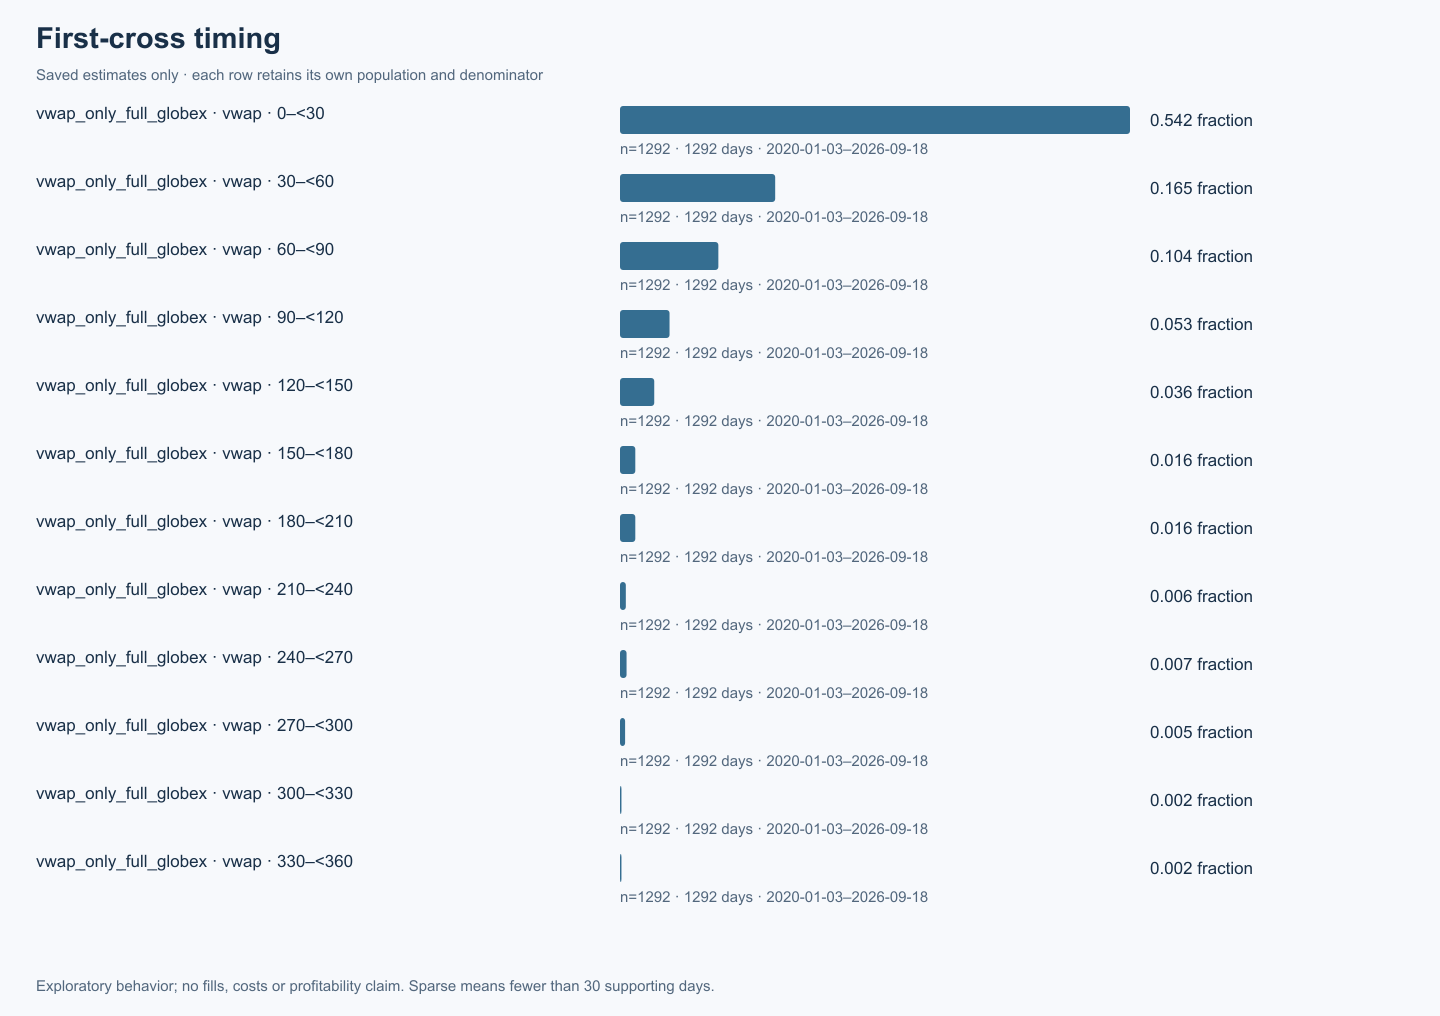

In [29]:
show_insight('vwap', 's12')


## Does RTH followthrough change with VWAP crossing order?

Group the first, second and third-or-later EMA6–VWAP crossings within each RTH day and retain complete 30-minute directional outcomes. Later events can share a day, so these groups are dependent exploratory slices.

**Findings summary.** Saved mean 30-minute displacement was 0.04 ES points after the first crossing (1,030 outcomes), 0.06 after the second (809 outcomes), and -0.02 after third-or-later crossings. Denominators and censoring differ across these groups.

In [30]:
show_insight('vwap', 's13')


Saved measure and context,Mean,Observations,Days,Unavailable,Censored
VWAP-only RTH · overall: all · Displacement [points] · EMA6–VWAP · 30m · crossing ordinal=1,0.035,"1,030","1,030",8,8
VWAP-only RTH · overall: all · Displacement [points] · EMA6–VWAP · 30m · crossing ordinal=2,0.059,809,809,25,25
VWAP-only RTH · overall: all · Displacement [points] · EMA6–VWAP · 30m · crossing ordinal=3+,-0.015,"1,712",601,199,199


## How do cloud states relate to RTH VWAP-cross outcomes?

At each actual RTH EMA6–VWAP crossing, classify the five-minute cloud by ordering and both 15-minute slopes. Keep supporting, opposing, mixed/flat and unknown states distinct, then read complete 30-minute outcomes.

**Findings summary.** Mean directional displacement was -0.35 ES points with cloud support (569 complete outcomes) and -0.15 with cloud opposition (563 outcomes). These are exploratory conditional observations, with mixed and unknown states retained separately in the earlier Ranked statistics reports.

In [31]:
show_insight('vwap', 's16')


Saved measure and context,Mean,Observations,Days,Unavailable,Censored
VWAP-only RTH · overall: all · Displacement [points] · EMA6–VWAP · 30m · cloud support=support,-0.354,569,396,53,53
VWAP-only RTH · overall: all · Displacement [points] · EMA6–VWAP · 30m · cloud support=opposition,-0.147,563,392,35,35


## How persistent are RTH section-end states?

Compare observed price-side and cloud-ordering states from the opening-range endpoint to AM and PM endpoints in the pivot-independent RTH population. Later endpoint states cannot be used as opening-time conditions.

**Findings summary.** Bullish cloud ordering persisted from the opening-range endpoint to the AM endpoint on 74.4% of 687 eligible bullish-source RTH days; bearish ordering persisted on 68.4% of 621 bearish-source days. The chart retains selected saved transition views.

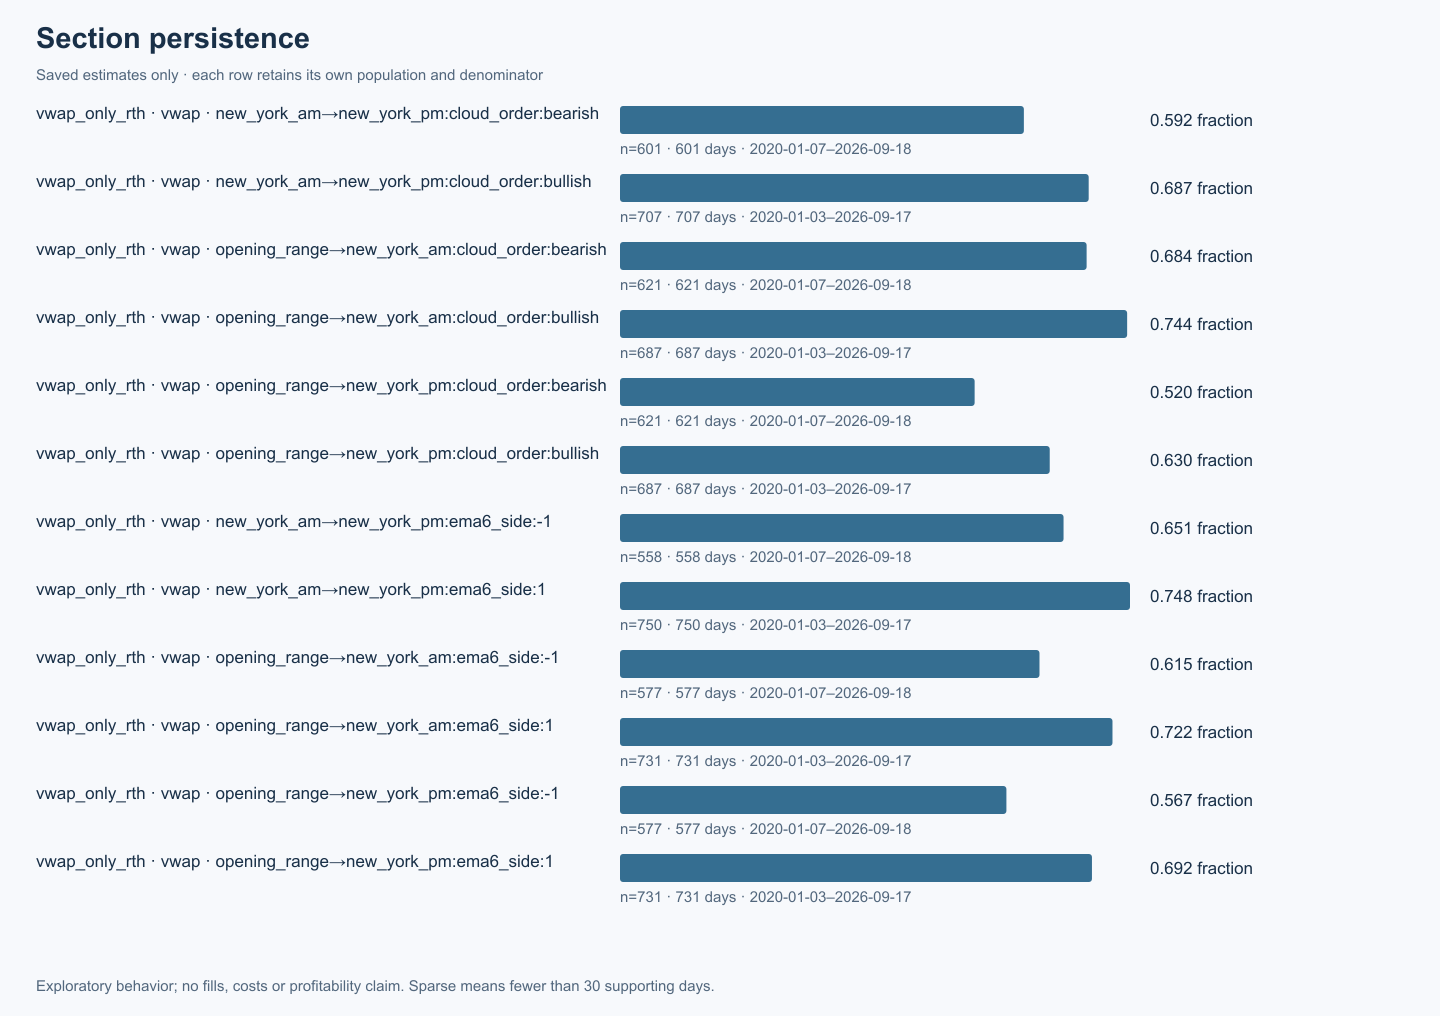

In [32]:
show_insight('vwap', 's19')


## How does recent Globex crossing activity compare with earlier history?

Compare trailing 20, 60 and 120 eligible observed sessions with disjoint earlier histories. Globex and RTH remain separate, and the latest available date is September 18, 2026 despite the October 30 requested cutoff.

**Findings summary.** Full-Globex EMA6–VWAP crossings averaged 11.15 per session over the last 20 eligible sessions, versus 10.78 over the preceding 1,272 sessions. The 20-session cell is sparse under the study’s 30-day rule; the chart also preserves the other selected windows.

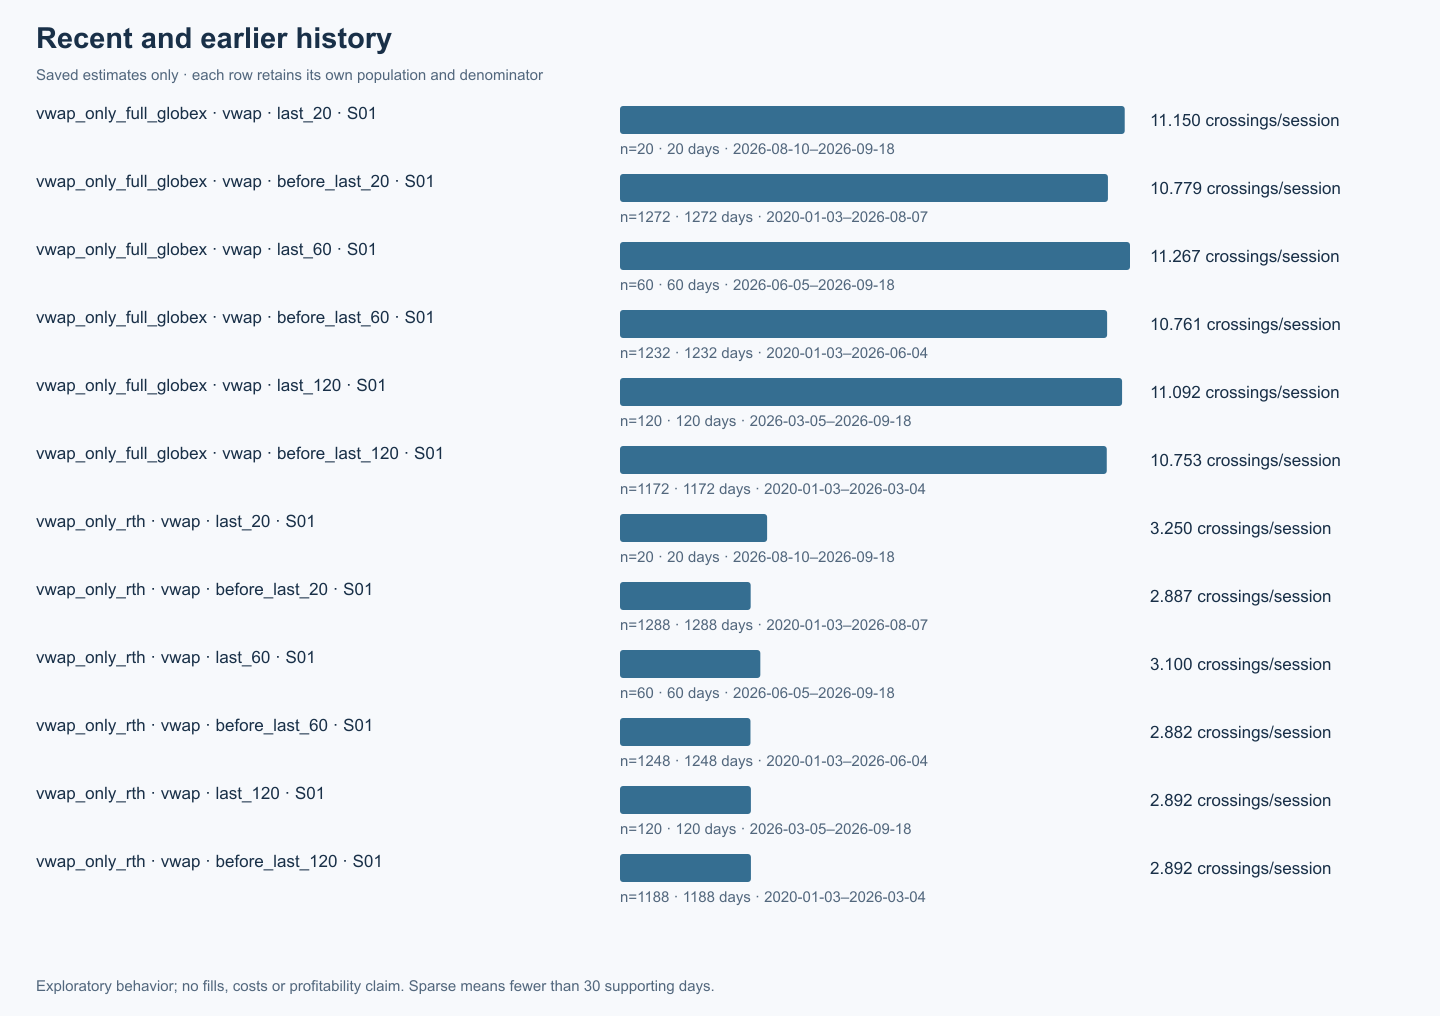

In [33]:
show_insight('vwap', 's20')


## Evidence qualifications

Repository-retained ES data only; requested coverage ends 2026-10-30, while retained market data ends 2026-09-18. Missing dates/contracts and retrospective full-day eligibility limit generalization.

Historical pivot available_at remains unverified. Nominal 09:25 timing does not establish a historically executable pre-open signal.

Returned-without-EMA and eventual confirmation labels are known later. Already-aligned EMA6 is distinct from an actual new line crossing.

Signed displacement and excursions describe price paths. No entries, fills, costs or net profitability are tested. Broad slices are exploratory.

This extends an already observed completed study and is not an untouched holdout. EMA–VWAP crossings use the moving difference, carry strict side through equality, clear unknown comparisons and exclude anchor initialization. EMA recrosses are separate from price reversals. Pivot retests remain fixed-pivot only. Five-observed-session moving-block intervals use 2,000 replicates, seed 20261031; within-day events remain together. Broad conditional slices are exploratory.